# 06 · Inference: sampling, KV-cache, speculative decoding, serving math

**What you will learn**
- Prefill vs decode and why decode is memory-bandwidth-bound
- Sampling strategies (greedy, temperature, top-k, top-p, repetition penalty) and their effect
- Measuring the KV-cache speed-up, and sizing cache memory for real models
- **Speculative decoding** implemented from scratch, with acceptance-rate measurement
- Batched generation; what vLLM/SGLang add (PagedAttention, continuous batching, prefix caching)
- Evaluation: TTFT, tokens/s, and checking that optimizations do not change outputs

**Source:** `llm_edu_suite/model.py` (`generate`, `sample_next_token`), `llm_edu_suite/inference.py`.

## Background: the two phases of generation

A causal LM produces one token per forward pass, feeds it back, and repeats. That loop has two very different phases:

```
prompt (P tokens)          generated tokens, one per step
[ t1 t2 ... tP ]  ---->  y1 ---> y2 ---> y3 ---> ... ---> yN
 \___ prefill ___/        \__________ decode _____________/
 one pass, all P tokens   N passes, one new token each
 matrix x matrix          matrix x vector
 compute-bound            memory-bandwidth-bound
```

- **Prefill** processes the whole prompt in one pass. Every weight matrix is multiplied by a $P \times C$ block of activations, so each weight read from memory is used $P$ times. The GPU's arithmetic units are busy: prefill is **compute-bound** and determines the **time to first token (TTFT)**.
- **Decode** produces one token per pass. Every weight is read from memory to be used for a single vector (or for $B$ vectors with batch size $B$). Reading the weights takes far longer than the arithmetic: decode is **memory-bandwidth-bound** and determines the **time per output token (TPOT)**.

### Arithmetic intensity, in one line

For a model with $N$ parameters stored in bf16 (2 bytes each), one decode step for a batch of $B$ sequences performs about $2NB$ FLOPs and reads at least $2N$ bytes of weights:

$$\text{arithmetic intensity} \approx \frac{2NB}{2N} = B \ \text{FLOPs per byte}$$

A modern datacenter GPU can do on the order of a hundred or more FLOPs in the time it reads one byte from memory (its "ridge point" in the roofline model of Williams et al., 2009). At $B = 1$ the GPU is therefore idle most of the time, waiting for memory. This single fact explains most of this notebook:
- the speed ceiling at batch 1 is roughly **memory bandwidth / model size in bytes** (a 7B model in bf16 is 14 GB, so a GPU with 1 TB/s cannot exceed about 70 tokens/s for one sequence, whatever its FLOPs);
- **batching** is almost free until $B$ approaches the ridge point, because the same weight read serves $B$ sequences;
- **quantization** (notebook 09) speeds up decode by reducing the bytes, not the FLOPs;
- **speculative decoding** exploits the idle compute by checking several tokens per weight read.

Pope et al. (2022), *Efficiently Scaling Transformer Inference*, is the standard reference for this analysis.

## Background: decoding strategies

The model outputs logits $z \in \mathbb{R}^V$ for the next token. A **decoding strategy** turns them into a choice. There are two families.

**Mode-seeking** methods look for the most probable text. **Greedy** decoding takes $\arg\max_i z_i$ at each step. **Beam search** keeps the $b$ best partial sequences and approximates the most probable *sequence*. They work well when there is one correct answer (translation, extraction, short factual answers), but for open-ended text they produce bland, repetitive output. Holtzman et al. (2020) showed that maximizing likelihood leads to text that is *more* predictable than anything a human writes, and that repetition is self-reinforcing: once a phrase repeats, the model assigns it even higher probability.

**Sampling** methods draw from the distribution, usually after reshaping it:

**Temperature** divides the logits before the softmax:

$$p_i(T) = \frac{e^{z_i / T}}{\sum_j e^{z_j / T}}$$

$T < 1$ sharpens the distribution (as $T \to 0$ it becomes greedy), $T > 1$ flattens it (as $T \to \infty$ it becomes uniform). Temperature never changes the *ranking* of tokens, only how much mass the top tokens get. The name and the formula come from the Boltzmann distribution in statistical physics.

**Truncation** removes the unreliable tail. The tail of an LLM's distribution contains thousands of tokens that are each very unlikely but together can hold a few percent of the mass; sample from it once and the text can derail, after which the model conditions on its own mistake.
- **Top-k** (Fan, Lewis, Dauphin, 2018) keeps the $k$ most likely tokens. Its weakness is that $k$ is fixed: too many candidates when the model is sure, too few when many continuations are reasonable.
- **Top-p / nucleus** (Holtzman et al., 2020) keeps the smallest set $V_p$ whose total probability reaches $p$, then renormalizes:
$$V_p = \text{smallest } S \text{ with } \sum_{i \in S} p_i \ge p, \qquad \tilde p_i = \frac{p_i \,\mathbb{1}[i \in V_p]}{\sum_{j \in V_p} p_j}$$
  The candidate set adapts to the model's confidence, which is why top-p replaced top-k as the default in most APIs.
- **Min-p** (Nguyen et al., 2024) keeps tokens with $p_i \ge p_{min} \cdot \max_j p_j$, a threshold relative to the top token. It is popular in open-source inference tools, particularly at higher temperatures; how much it improves over top-p is still discussed.

**Repetition control.** The repetition penalty from CTRL (Keskar et al., 2019) divides the positive logits of already-generated tokens by $\theta > 1$ (and multiplies negative ones), making them less likely. The OpenAI-style *presence* and *frequency* penalties instead subtract a constant, or a constant times the count, from those logits. Both are blunt: they also punish repetition that is correct, such as a variable name in code or a name in a story.

| strategy | parameter | adapts to confidence? | typical use |
|---|---|---|---|
| greedy / beam | beam width | no | extraction, translation, deterministic evals |
| temperature | $T$ | no (rescales everything) | always combined with one of the below |
| top-k | $k$ | no | older default (GPT-2 era) |
| top-p | $p$ | yes | default for chat (often $T \approx 0.7$, $p \approx 0.9$) |
| min-p | $p_{min}$ | yes | open-source runtimes, creative writing |

Two practical notes. The **order** in which libraries apply temperature, top-k and top-p differs, so the same parameter values can give slightly different distributions in different engines. And **$T = 0$ is not perfectly deterministic** in a production server: the floating-point result of a matmul can depend on the batch it was computed in, so near-ties can flip between runs. Structured output (notebook 11) is also a decoding strategy: it masks the logits of every token that would violate a grammar or JSON schema.

## Background: the KV-cache

In causal attention, the key and value vectors of a past position never change once computed, because they depend only on tokens up to that position. Recomputing them at every step is pure waste, so every inference engine stores them in a **KV-cache**. Without it, step $t$ recomputes projections for all $t$ previous tokens, $O(N^2)$ projection work for $N$ tokens; with it, each step computes projections for one new token and attends over the cached ones, $O(N)$ projection work in total (the attention itself still reads all $t$ cached entries per step).

The cache is not free. Per token it stores keys and values for every layer and KV head:

$$\text{bytes per token} = 2 \times n_{layers} \times n_{kv\_heads} \times d_{head} \times \text{bytes per value}$$

and the total grows with context length times batch size. In serving, the cache, not the weights, usually decides how many sequences fit on a GPU. That is why so many architecture changes target it: multi-query attention (Shazeer, 2019), grouped-query attention (Ainslie et al., 2023), multi-head latent attention (DeepSeek-V2, 2024), sliding-window attention, and fp8 KV-cache quantization.

## Background: serving many users

| technique | problem it solves | key reference |
|---|---|---|
| static batching | weight reads are amortized over the batch | — |
| continuous (iteration-level) batching | in static batching, finished sequences leave idle slots until the longest one ends; here the scheduler adds and removes sequences at every decode step | Yu et al. (2022), *Orca* |
| PagedAttention | contiguous per-sequence cache buffers waste memory to fragmentation and over-reservation; storing the cache in fixed-size blocks with a block table (like virtual memory pages) nearly eliminates the waste and allows sharing blocks | Kwon et al. (2023), *Efficient Memory Management for Large Language Model Serving with PagedAttention* (vLLM) |
| prefix caching | many requests share a system prompt or few-shot examples; reuse their KV blocks instead of re-running prefill | Zheng et al. (2024), *SGLang* (RadixAttention) |
| chunked prefill | a long prompt's prefill stalls all decoding sequences; split it into chunks mixed with decode steps | Agrawal et al. (2024), *Sarathi-Serve* |
| prefill/decode disaggregation | the two phases want different hardware trade-offs; run them on separate GPU pools | Zhong et al. (2024), *DistServe* |
| CUDA graphs | kernel launch overhead dominates small decode steps; record the step once and replay it | — |

vLLM, SGLang and TensorRT-LLM combine most of these. The metrics they are tuned for are TTFT, TPOT, throughput at a given latency target (often called "goodput"), and cost per million tokens.

## Background: speculative decoding and why it is exact

Decode leaves the GPU's compute idle, and the target model can score $k+1$ positions in one pass for nearly the cost of one. Speculative decoding (Leviathan, Kalman, Matias, 2023; and independently Chen et al., 2023, under the name speculative sampling; an earlier greedy-only form is Stern, Shazeer, Uszkoreit, 2018) turns that into speed:

```
draft  (small, fast):  proposes  d1 d2 d3 d4          (k = 4 cheap steps)
target (big, exact):   one pass scores positions 1..5 in parallel
                       accept d1  accept d2  reject d3 -> resample from residual
output this round:     d1 d2 r3                       (3 tokens for 1 target pass)
```

For each proposed token $x \sim q(\cdot)$ (draft distribution) with target distribution $p(\cdot)$ at the same position:
1. accept $x$ with probability $\min\big(1, \tfrac{p(x)}{q(x)}\big)$;
2. at the first rejection, sample a replacement from the **residual distribution** $p'(x) = \dfrac{\max(0,\, p(x) - q(x))}{\sum_y \max(0,\, p(y) - q(y))}$ and stop the round;
3. if all $k$ are accepted, sample one bonus token from the target's distribution at position $k+1$, which the same pass already computed.

**Why the output distribution is exactly $p$.** Let $\beta = \sum_y \min(p(y), q(y))$ be the total acceptance probability. The probability of emitting token $x$ is the probability of proposing and accepting it, plus the probability of rejecting and then resampling it:

$$P(x) = q(x)\min\Big(1, \frac{p(x)}{q(x)}\Big) + (1-\beta)\,p'(x) = \min(p(x), q(x)) + \max(0, p(x) - q(x)) = p(x)$$

using $1 - \beta = \sum_y \max(0, p(y) - q(y))$. No approximation is involved: a bad draft makes the method slow, never wrong. Note that $\beta = 1 - \text{TV}(p, q)$, so the per-token acceptance rate is one minus the total variation distance between draft and target.

**Expected speed-up.** If each token is accepted independently with probability $\alpha$, the expected number of tokens produced per target pass is

$$\mathbb{E}[\text{tokens per round}] = \frac{1 - \alpha^{k+1}}{1 - \alpha}$$

which tends to $k+1$ as $\alpha \to 1$. The wall-clock gain is smaller, because the draft's $k$ forward passes are not free; Leviathan et al. derive the improvement factor $\frac{1-\alpha^{k+1}}{(1-\alpha)(kc+1)}$ where $c$ is the cost of one draft step relative to one target step. So you want a draft that is both cheap (small $c$) and well aligned with the target (large $\alpha$), and $k$ is tuned between the two.

**When it does not help.** At large batch sizes decode is no longer memory-bound, the spare compute disappears, and the extra verification work competes with real requests. Acceptance also drops at high temperature (both distributions are flatter and disagree more) and on text the draft model knows poorly. The draft must use the same tokenizer as the target.

**Modern variants** remove the separate draft model: Medusa (Cai et al., 2024) adds extra decoding heads to the target, EAGLE (Li et al., 2024) drafts from the target's own hidden features, prompt-lookup / n-gram drafting copies spans from the context (very effective for editing and RAG), and DeepSeek-V3's multi-token-prediction module can be reused as a draft. All of them keep the same accept/reject rule, which is what guarantees correctness.

### Key papers

- Holtzman, Buys, Du, Forbes, Choi (2020), *The Curious Case of Neural Text Degeneration*.
- Fan, Lewis, Dauphin (2018), *Hierarchical Neural Story Generation*.
- Keskar et al. (2019), *CTRL: A Conditional Transformer Language Model for Controllable Generation*.
- Pope et al. (2022), *Efficiently Scaling Transformer Inference*.
- Shazeer (2019), *Fast Transformer Decoding: One Write-Head is All You Need*.
- Ainslie et al. (2023), *GQA: Training Generalized Multi-Query Transformer Models from Multi-Head Checkpoints*.
- Yu et al. (2022), *Orca: A Distributed Serving System for Transformer-Based Generative Models*.
- Kwon et al. (2023), *Efficient Memory Management for Large Language Model Serving with PagedAttention*.
- Leviathan, Kalman, Matias (2023), *Fast Inference from Transformers via Speculative Decoding*.
- Chen et al. (2023), *Accelerating Large Language Model Decoding with Speculative Sampling*.
- Cai et al. (2024), *Medusa*; Li et al. (2024), *EAGLE*.

In [1]:
import os, sys, math, time, tempfile
ROOT = os.path.abspath(".")
while not os.path.isdir(os.path.join(ROOT, "llm_edu_suite")) and os.path.dirname(ROOT) != ROOT:
    ROOT = os.path.dirname(ROOT)                    # notebooks live in notebooks/<topic>/, so climb up to the repo root
sys.path.insert(0, ROOT)                            # so that `import llm_edu_suite` works from the notebook
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from llm_edu_suite.utils import seed_everything, get_device, count_params, human, show_mask
seed_everything(0)
device = get_device()
print("torch", torch.__version__, "| device", device)

torch 2.14.1+cu130 | device cuda


In [2]:
# Train a small target model and an even smaller draft model on the same data. Each takes a few seconds.
from llm_edu_suite.model import ModelConfig, TransformerLM
from llm_edu_suite.data import synthetic_structured_corpus, train_val_split
from llm_edu_suite.training import TrainConfig, train_lm

data = synthetic_structured_corpus(n_tokens=150_000, vocab=512, n_words=80)
train_data, val_data = train_val_split(data)
tcfg = TrainConfig(steps=400, batch_size=32, block_size=64, max_lr=3e-3, warmup=40, eval_every=400, log=False)

seed_everything(0); target = TransformerLM(ModelConfig(vocab_size=512, d_model=192, n_layers=6, n_heads=6, n_kv_heads=2)); train_lm(target, train_data, val_data, tcfg, device)
seed_everything(0); draft  = TransformerLM(ModelConfig(vocab_size=512, d_model=64,  n_layers=2, n_heads=4, n_kv_heads=2)); train_lm(draft,  train_data, val_data, tcfg, device)
print(f"target {human(target.num_params())} params | draft {human(draft.num_params())} params")

target 2.46M params | draft 125.25K params


## 1. Sampling
The model gives a distribution over `V`; the decoding strategy picks a token. Typical: chat `T=0.7, top_p=0.9`; code/math `T≈0`; RL rollouts `T=1`.

| strategy | what it does to the distribution | effect |
|---|---|---|
| greedy (`T=0`) | always the argmax | deterministic, prone to loops |
| temperature `T` | `softmax(logits / T)` | `T<1` sharper, `T>1` flatter |
| top-k | keep the k most likely tokens | cuts the long tail at a fixed size |
| top-p (nucleus) | keep the smallest set with cumulative prob ≥ p | adaptive: few tokens when confident, many when unsure |
| repetition penalty | down-weights tokens already generated | fewer loops, can hurt when repetition is correct |

In our synthetic language a "word" is a fixed sequence of 2–4 tokens and words are separated by `0`. **Inside** a word the next token is almost certain (all strategies agree); **right after a `0`** the model must choose among ~80 words — that is where the strategies differ. We look at that position.

**What the cell measures.** For each strategy it prints how many tokens keep non-zero probability (truncation), the probability of the top token (sharpness) and the **entropy** $H = -\sum_i p_i \log p_i$ in nats. Entropy is the cleanest single number for "how random will the next token be": $e^{H}$ is the effective number of equally likely choices, so a uniform choice among 80 words would give $H = \ln 80 \approx 4.4$ nats. Temperature changes entropy smoothly and keeps every candidate alive; top-k and top-p cut candidates to zero and renormalize the survivors, which also raises their individual probabilities.

T=1.0           : candidates with p>0  512 | top-1 prob 0.036 | entropy 4.25 nats
T=0.7           : candidates with p>0  512 | top-1 prob 0.052 | entropy 4.18 nats
T=0.7 top-k 20  : candidates with p>0   20 | top-1 prob 0.121 | entropy 2.89 nats
T=0.7 top-p 0.9 : candidates with p>0   61 | top-1 prob 0.058 | entropy 4.01 nats
T=1.5           : candidates with p>0  512 | top-1 prob 0.026 | entropy 4.36 nats


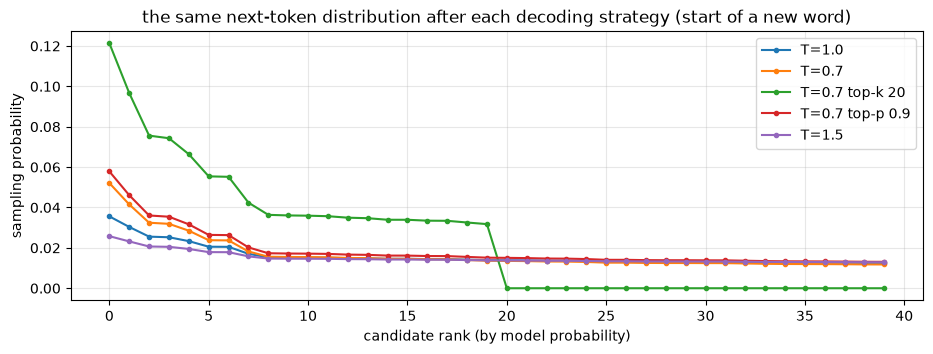

In [3]:
from llm_edu_suite.model import next_token_distribution

# Find a context that ends with the separator 0, so the next token starts a new word and the model is genuinely uncertain.
pos = int((val_data[40:] == 0).nonzero()[0]) + 40          # start at 40 so the 32-token window below fits
ctx = val_data[pos - 31 : pos + 1].unsqueeze(0).to(device)
with torch.no_grad():
    logits = target(ctx)[0][:, -1, :]

strategies = {"T=1.0": dict(temperature=1.0), "T=0.7": dict(temperature=0.7), "T=0.7 top-k 20": dict(temperature=0.7, top_k=20),
              "T=0.7 top-p 0.9": dict(temperature=0.7, top_p=0.9), "T=1.5": dict(temperature=1.5)}
fig, ax = plt.subplots(figsize=(11, 3.5))
order = logits[0].argsort(descending=True)[:40]
for name, kw in strategies.items():
    p = next_token_distribution(logits, **kw)[0]
    ent = -(p[p > 0] * p[p > 0].log()).sum().item()
    print(f"{name:16s}: candidates with p>0 {int((p > 0).sum()):4d} | top-1 prob {p.max().item():.3f} | entropy {ent:.2f} nats")
    ax.plot(range(40), p[order].cpu(), "o-", ms=3, label=name)
ax.set_xlabel("candidate rank (by model probability)"); ax.set_ylabel("sampling probability")
ax.set_title("the same next-token distribution after each decoding strategy (start of a new word)"); ax.legend(); ax.grid(alpha=.3)
plt.show()

In [4]:
# Measure diversity across 16 continuations of the same prompt. distinct-2 = unique bigrams / all bigrams.
def distinct_n(seqs, n=2):
    grams = [tuple(s[i:i + n]) for s in seqs for i in range(len(s) - n + 1)]
    return len(set(grams)) / max(1, len(grams))

prompt = ctx[:, -8:]
rows = {"greedy": dict(temperature=0), **strategies, "T=0.7 rep. penalty 1.5": dict(temperature=0.7, repetition_penalty=1.5)}
for name, kw in rows.items():
    torch.manual_seed(0)
    outs = [target.generate(prompt, 24, **kw)[0, 8:].tolist() for _ in range(16)]
    print(f"{name:24s} distinct-2 {distinct_n(outs):.2f} | unique continuations {len(set(map(tuple, outs))):2d}/16 | e.g. {outs[0][:12]}")

greedy                   distinct-2 0.02 | unique continuations  1/16 | e.g. [258, 193, 13, 0, 228, 103, 82, 0, 258, 193, 13, 0]


T=1.0                    distinct-2 0.62 | unique continuations 16/16 | e.g. [243, 399, 222, 183, 0, 379, 408, 376, 0, 317, 468, 0]


T=0.7                    distinct-2 0.59 | unique continuations 16/16 | e.g. [243, 399, 222, 183, 0, 379, 408, 376, 0, 317, 468, 0]


T=0.7 top-k 20           distinct-2 0.42 | unique continuations 16/16 | e.g. [243, 399, 222, 183, 0, 145, 369, 498, 491, 0, 258, 193]


T=0.7 top-p 0.9          distinct-2 0.60 | unique continuations 16/16 | e.g. [243, 399, 222, 183, 0, 156, 140, 0, 413, 9, 0, 426]


T=1.5                    distinct-2 0.64 | unique continuations 16/16 | e.g. [243, 399, 222, 183, 0, 379, 408, 376, 0, 284, 354, 96]


T=0.7 rep. penalty 1.5   distinct-2 0.60 | unique continuations 16/16 | e.g. [243, 399, 222, 183, 0, 379, 408, 376, 0, 317, 468, 0]


**Reading the results.** Lower temperature and tighter top-k/top-p concentrate the probability mass (higher top-1 prob, lower entropy) and reduce diversity; `T=1.5` flattens the distribution and gives the most varied — and least faithful — continuations. Greedy produces one continuation 16 times. Pick the strategy per task and **measure** diversity and quality together: more diversity is only good while the outputs stay correct.

## 2. KV-cache: same output, far less work
Without the cache, generating N tokens recomputes k/v for every past token at every step (O(N²) projections). With it, O(N). We verify equality and time both.

The equality check is the important half. A KV-cache is an *exact* optimization: with greedy decoding, the cached and uncached paths must produce the same tokens, because they compute the same function. Small floating-point differences between the two code paths can in principle flip a near-tie, which is why serious engines test cache correctness on many prompts. The second cell then sizes the cache with the formula from the Background, $2 \times n_{layers} \times n_{kv\_heads} \times d_{head} \times 2$ bytes in bf16, to show how much KV-sharing (GQA) and compression (MLA) reduce it.

In [5]:
import time
def generate_no_cache(model, idx, n):
    model.eval()
    for _ in range(n):
        logits, _ = model(idx)                                  # recomputes the whole prefix at every step
        idx = torch.cat([idx, logits[:, -1].argmax(-1, keepdim=True)], 1)
    return idx

prompt = val_data[:16].unsqueeze(0).to(device)
t0 = time.perf_counter(); a = generate_no_cache(target, prompt, 100); t_nc = time.perf_counter() - t0
t0 = time.perf_counter(); b = target.generate(prompt, 100, temperature=0); t_c = time.perf_counter() - t0
print("identical outputs:", torch.equal(a, b))
print(f"no cache {t_nc*1000:.0f} ms | with cache {t_c*1000:.0f} ms | speed-up {t_nc / t_c:.1f}x  (grows with sequence length)")

identical outputs: True
no cache 846 ms | with cache 724 ms | speed-up 1.2x  (grows with sequence length)


In [6]:
from llm_edu_suite.inference import kv_cache_memory
for name, args in {"70B with MHA (64 KV)": dict(n_layers=80, n_kv_heads=64, head_dim=128), "Llama-3-70B (GQA 8)": dict(n_layers=80, n_kv_heads=8, head_dim=128),
                   "Llama-3-8B (GQA 8)": dict(n_layers=32, n_kv_heads=8, head_dim=128)}.items():
    m = kv_cache_memory(context=8192, batch=1, **args)
    print(f"{name:20s} {m['bytes_per_token']/1024:6.0f} KB/token -> {m['total_gb']:5.1f} GB for one 8k-token sequence")
print("\nDeepSeek-V3 MLA: 61 layers x 576 values x 2 bytes =", 61 * 576 * 2 / 1024, "KB/token")

70B with MHA (64 KV)   2560 KB/token ->  20.0 GB for one 8k-token sequence
Llama-3-70B (GQA 8)     320 KB/token ->   2.5 GB for one 8k-token sequence
Llama-3-8B (GQA 8)      128 KB/token ->   1.0 GB for one 8k-token sequence

DeepSeek-V3 MLA: 61 layers x 576 values x 2 bytes = 68.625 KB/token


## 3. Speculative decoding

Decode is memory-bound: verifying `k` tokens costs about the same as generating 1. So let a cheap **draft** propose `k` tokens, and have the **target** verify them in one forward pass, accepting each with probability `min(1, p/q)` and resampling from `norm(max(0, p−q))` at the first rejection. The output distribution is *exactly* the target's; speed comes from accepting several tokens per target call.

**What to expect from the numbers.** With $k = 4$ the ceiling is $k + 1 = 5$ tokens per target pass, reached only when every draft token is accepted. Under the independence assumption from the Background, the expected value is $(1 - \alpha^{5}) / (1 - \alpha)$ for acceptance rate $\alpha$, so you can check the measured `tokens_per_round` against the measured `acceptance_rate`. Our synthetic language is highly predictable inside words, which favours a high acceptance rate; real chat text at temperature 1 with a much smaller draft typically gives lower values. Remember that tokens per round is not wall-clock speed-up: on real hardware you would also pay for the draft's $k$ forward passes.

In [7]:
from llm_edu_suite.inference import speculative_decode

prompt = val_data[:8].unsqueeze(0).to(device)
torch.manual_seed(0)
out, stats = speculative_decode(target, draft, prompt, max_new_tokens=60, k=4, temperature=1.0)
print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in stats.items()})
print("generated:", out[0, 8:].tolist()[:30], "...")
print(f"\n-> {stats['tokens_per_round']:.2f} tokens per target forward pass (plain decoding = 1.0). "
      f"Acceptance rate {stats['acceptance_rate']:.0%}: the better the draft approximates the target, the bigger the win.")

{'proposed': 48, 'accepted': 47, 'rounds': 13, 'acceptance_rate': 0.979, 'tokens_per_round': 4.615}
generated: [65, 479, 140, 0, 417, 468, 508, 279, 0, 317, 468, 0, 95, 253, 312, 0, 228, 103, 82, 0, 113, 68, 503, 0, 163, 150, 122, 0, 327, 115] ...

-> 4.62 tokens per target forward pass (plain decoding = 1.0). Acceptance rate 98%: the better the draft approximates the target, the bigger the win.


### Does speculative decoding change the distribution?
It must not. We sample many next-token continuations with both methods and compare the empirical distributions over the first generated token (a statistical check, not a proof — the proof is in the paper).

**How close is "close enough"?** Each frequency is an estimate from $N = 400$ samples, so its standard error is $\sqrt{p(1-p)/N}$, at most $\sqrt{0.25/400} = 0.025$. Two correct samplers will therefore disagree by a couple of percentage points just by chance; a systematic gap several times larger than that would point to a bug, for example forgetting to renormalize the residual distribution. A more formal version of this test is a chi-squared test on the two count tables.

In [8]:
from collections import Counter
torch.manual_seed(1)
N = 400
plain = Counter(target.generate(prompt, 1, temperature=1.0)[0, -1].item() for _ in range(N))
spec = Counter(speculative_decode(target, draft, prompt, max_new_tokens=2, k=1, temperature=1.0)[0][0, prompt.shape[1]].item() for _ in range(N))
top = [t for t, _ in (plain + spec).most_common(6)]
print("token  : plain  spec")
for t in top:
    print(f"{t:6d} : {plain[t]/N:5.2f}  {spec[t]/N:5.2f}")

token  : plain  spec
    65 :  0.54   0.55
    82 :  0.47   0.45


## 4. Batched generation
Serving many users means batching: one weight read serves many sequences. The simple version left-pads prompts; real engines (vLLM) use **PagedAttention** (cache in non-contiguous pages, no fragmentation), **continuous batching** (new requests join mid-flight), **prefix caching** (shared system prompts computed once), and **chunked prefill** so long prompts don't stall others.

**Why left padding.** In a batch, prompts have different lengths, but a decoder generates at the *end* of each row. Padding on the left aligns every prompt's last token in the same column, so each step appends one new column for the whole batch. The padded positions must be masked out of attention (and position ids adjusted), otherwise the model would attend to pad tokens and its outputs would differ from unbatched generation. The demo `batched_generate` keeps things minimal and does neither (its docstring says so); in the cell below every prompt has the same 8 tokens, so no padding actually occurs and the issue does not arise. Padding also wastes compute on positions that carry no information, which is one of the inefficiencies that continuous batching and PagedAttention remove: they let each sequence occupy exactly the cache it needs.

In [9]:
from llm_edu_suite.inference import batched_generate
prompts = [val_data[i:i+8].tolist() for i in range(0, 64, 8)]
t0 = time.perf_counter(); outs = batched_generate(target, prompts, 32, pad_id=0, temperature=0.0); dt = time.perf_counter() - t0
print(f"{len(prompts)} prompts x 32 tokens in {dt*1000:.0f} ms -> {len(prompts)*32/dt:.0f} tokens/s aggregate (no cache, recompute mode)")
print("first output:", outs[0][:16])

8 prompts x 32 tokens in 251 ms -> 1021 tokens/s aggregate (no cache, recompute mode)
first output: [65, 479, 140, 258, 193, 13, 256, 138, 258, 193, 511, 145, 369, 498, 491, 258]


## 5. Evaluation: latency and throughput

The serving metrics: **TTFT** (time to first token; prefill-bound), **tokens/s per sequence** (decode-bound), **aggregate throughput** (grows with batch), and **cost per 1M tokens**. Always report them *together with* a quality check — an optimization that changes outputs is a bug, not a speed-up.

**The latency-throughput trade-off.** Total generation time for one request is roughly $\text{TTFT} + N_{out} \times \text{TPOT}$. Batching raises aggregate throughput (tokens per second across all users) almost for free while decode is memory-bound, but once the batch is large enough to make each step compute-bound, every extra sequence makes the step slower and TPOT grows for everyone. A serving system therefore picks an operating point: the largest batch that still meets the latency target (for example, a TTFT and TPOT budget at the 99th percentile). Benchmarks that report only peak throughput, or only single-request latency, hide that choice.

In [10]:
from llm_edu_suite.evaluation import benchmark_generation
for B in (1, 4, 16):
    p = val_data[:8].repeat(B, 1).to(device)
    r = benchmark_generation(target, p, max_new_tokens=48, n_runs=2, temperature=0)
    print(f"batch {B:2d}: TTFT {r['ttft_ms']:6.1f} ms | {r['tokens_per_s']:7.0f} tokens/s aggregate")
print("\nAggregate throughput grows almost linearly with batch size while per-sequence speed barely drops: decode is memory-bound.")

batch  1: TTFT   14.1 ms |     137 tokens/s aggregate


batch  4: TTFT   14.7 ms |     526 tokens/s aggregate


batch 16: TTFT   14.2 ms |    2180 tokens/s aggregate

Aggregate throughput grows almost linearly with batch size while per-sequence speed barely drops: decode is memory-bound.


**A GPU caveat that is worth understanding.** With a model this small, each generated token launches dozens of tiny GPU kernels, and the fixed launch cost dominates the actual math. That is why, on a GPU, single-sequence decoding of a toy model can be no faster than on a CPU and the KV-cache speed-up looks modest: there is almost no compute to save. Batching amortizes the launch cost over many sequences, and that is exactly what serving engines do (vLLM's continuous batching, plus CUDA graphs to remove launch overhead). With real models (billions of parameters) the picture flips: the work per token is large, and the KV-cache and batching gains are dramatic.

**Takeaways**
- KV-cache is mandatory; GQA/MLA/quantized caches decide how many sequences fit.
- Speculative decoding gives 2–3× at low batch; its value shrinks as batch grows (the GPU is no longer idle).
- For production: `vllm serve <model> --enable-prefix-caching --kv-cache-dtype fp8` and measure TTFT/TPOT/throughput on *your* traffic.

**Next:** `07_finetuning_sft_lora.ipynb`.